# Dynamic Parking Assignment - Search Problem Formulation

This notebook implements the dynamic parking assignment as a formal Search Problem with:
- State representation: s = (v, t, A[t], C[t])
- Initial State, Actions, Transition Model, Goal Test, Path Cost
- Reinforcement Learning solution

## 1. Install and Import Required Libraries

In [26]:
#Install required packages (run once)
%pip install numpy pandas matplotlib networkx gymnasium

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from typing import Dict, List, Tuple, Optional, Set
import random
from collections import defaultdict
from dataclasses import dataclass
import copy

# For RL implementation
import gymnasium as gym
from gymnasium import spaces

# Set random seeds for reproducibility
np.random.seed(42)
random.seed(42)

## 2. Define the Search State

**State Definition:** s = (v, t, A[t], C[t])
- v: current node (vehicle position)
- t: current time step
- A[t]: availability status for each parking lot at time t
- C[t]: parking cost for each lot at time t

In [28]:
from dataclasses import dataclass

@dataclass
class SearchState:
    """Represents a state in the search problem: s = (v, t, A[t], C[t])"""
    v: int  # Current node (vehicle position)
    t: float  # Current time step
    A_t: Dict[int, int]  # Availability: parking_lot -> available_spots
    C_t: Dict[int, float]  # Cost: parking_lot -> parking_cost
    is_parked: bool = False  # Whether vehicle has parked
    parked_at: Optional[int] = None  # Which parking lot (if parked)
    
    def __hash__(self):
        """Make state hashable for use in visited sets"""
        availability_tuple = tuple(sorted(self.A_t.items()))
        cost_tuple = tuple(sorted(self.C_t.items()))
        return hash((self.v, round(self.t, 2), availability_tuple, cost_tuple, self.is_parked))
    
    def __eq__(self, other):
        """Check equality for state comparison"""
        if not isinstance(other, SearchState):
            return False
        return (self.v == other.v and 
                abs(self.t - other.t) < 0.01 and
                self.A_t == other.A_t and
                self.is_parked == other.is_parked)
    
    def copy(self):
        """Create a deep copy of the state"""
        return SearchState(
            v=self.v,
            t=self.t,
            A_t=self.A_t.copy(),
            C_t=self.C_t.copy(),
            is_parked=self.is_parked,
            parked_at=self.parked_at
        )
    
    def __repr__(self):
        return f"State(v={self.v}, t={self.t:.2f}, parked={self.is_parked})"

## 3. Define the Urban Road Network

**Graph G = (N, E)**
- N: nodes (intersections, origin S, destination D, parking lots P)
- E: directed edges with weights T_ij (travel time)

C:\Users\dragon slayer\AppData\Local\Temp\ipykernel_10864\2524928668.py:145: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Source (S): 0
Destination (D): 14
Parking lots (P): [11, 12, 13]
Base parking costs (C): {11: 7.857431808841254, 12: 7.792606390510127, 13: 19.899779641832133}


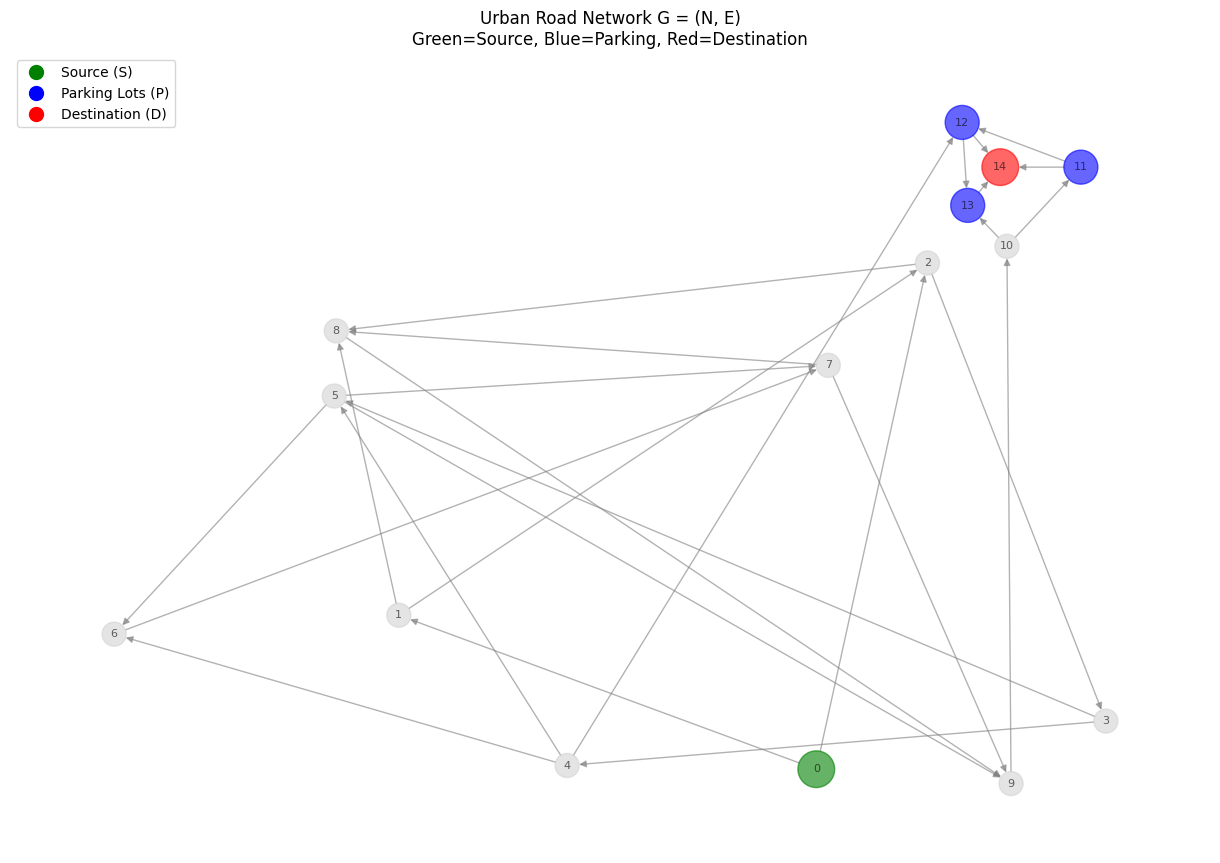

In [29]:

class UrbanRoadNetwork:
    """Represents the urban road network as a directed graph G = (N, E)"""
    
    def __init__(self, num_nodes=20, num_parking_lots=3):
        self.G = nx.DiGraph()
        self.num_nodes = num_nodes
        self.num_parking_lots = num_parking_lots
        
        # Special nodes
        self.S = 0  # Source (origin)
        self.D = num_nodes - 1  # Destination
        self.P = list(range(num_nodes - num_parking_lots - 1, num_nodes - 1))  # Parking lots
        
        # Node coordinates for walking distance calculation
        self.node_positions = {}
        
        # Initialize network
        self._create_network()
        self._assign_initial_travel_times()
        self._assign_base_parking_costs()
        
    def _create_network(self):
        """Create a realistic road network structure"""
        # Add all nodes with positions
        for i in range(self.num_nodes):
            self.G.add_node(i)
            # Assign 2D coordinates for walking distance
            self.node_positions[i] = (random.uniform(0, 10), random.uniform(0, 10))
        
        # Position destination at a specific location
        self.node_positions[self.D] = (8, 8)
        
        # Position parking lots near destination
        for i, p_k in enumerate(self.P):
            angle = 2 * np.pi * i / len(self.P)
            radius = random.uniform(0.3, 0.8)
            self.node_positions[p_k] = (
                8 + radius * np.cos(angle),
                8 + radius * np.sin(angle)
            )
        
        # Create edges (road segments)
        for i in range(self.num_nodes - 1):
            # Main path
            self.G.add_edge(i, i + 1)
            
        # Add some alternative routes
        for i in range(self.num_nodes - 2):
            if random.random() > 0.6:
                self.G.add_edge(i, i + 2)
                
        # Add cross connections
        for _ in range(self.num_nodes // 3):
            u = random.randint(0, self.num_nodes - 3)
            v = random.randint(u + 1, self.num_nodes - 1)
            if not self.G.has_edge(u, v):
                self.G.add_edge(u, v)
            
        # Ensure parking lots are connected to destination
        for p_k in self.P:
            if not self.G.has_edge(p_k, self.D):
                self.G.add_edge(p_k, self.D)
            
    def _assign_initial_travel_times(self):
        """Assign base travel times T_ij to edges"""
        for u, v in self.G.edges():
            # Base travel time between 2 and 8 minutes
            self.G[u][v]['T_base'] = random.uniform(2, 8)
            self.G[u][v]['T_current'] = self.G[u][v]['T_base']
            
    def _assign_base_parking_costs(self):
        """Assign base parking costs c_k to parking lots"""
        self.C_base = {}
        for p_k in self.P:
            # Base costs between $5 and $25
            self.C_base[p_k] = random.uniform(5, 25)
    
    def get_travel_time(self, u: int, v: int, t: float) -> float:
        """Get current travel time T_ij(t) with traffic variation"""
        if not self.G.has_edge(u, v):
            return float('inf')
        return self.G[u][v]['T_current']
    
    def update_traffic_conditions(self, t: float):
        """Update travel times T_ij based on time (simulating traffic)"""
        for u, v in self.G.edges():
            base_time = self.G[u][v]['T_base']
            # Traffic variation: ±40% of base time
            variation = random.uniform(0.6, 1.4)
            self.G[u][v]['T_current'] = base_time * variation
    
    def get_parking_cost(self, p_k: int, t: float) -> float:
        """Get parking cost c_k(t) which may vary with time"""
        base_cost = self.C_base[p_k]
        # Cost variation: ±20% based on time/demand
        variation = 1.0 + 0.2 * np.sin(t / 10)  # Oscillates with time
        return base_cost * variation
    
    def calculate_walking_distance(self, p_k: int, destination: int) -> float:
        """Calculate walking distance W(p_k, D) using Euclidean distance"""
        pos_pk = self.node_positions[p_k]
        pos_d = self.node_positions[destination]
        distance = np.sqrt((pos_pk[0] - pos_d[0])**2 + (pos_pk[1] - pos_d[1])**2)
        return distance  # in km
    
    def get_outgoing_edges(self, v: int) -> List[int]:
        """Get all nodes reachable from v (outgoing edges)"""
        return list(self.G.successors(v))
    
    def visualize_network(self):
        """Visualize the road network"""
        plt.figure(figsize=(12, 8))
        
        # Use the stored positions
        pos = self.node_positions
        
        # Draw different node types with different colors
        node_colors = []
        node_sizes = []
        for node in self.G.nodes():
            if node == self.S:
                node_colors.append('green')
                node_sizes.append(700)
            elif node == self.D:
                node_colors.append('red')
                node_sizes.append(700)
            elif node in self.P:
                node_colors.append('blue')
                node_sizes.append(600)
            else:
                node_colors.append('lightgray')
                node_sizes.append(300)
                
        nx.draw(self.G, pos, node_color=node_colors, node_size=node_sizes,
                with_labels=True, font_size=8, arrows=True, 
                edge_color='gray', alpha=0.6)
        
        # Add legend
        plt.plot([], [], 'o', color='green', markersize=10, label='Source (S)')
        plt.plot([], [], 'o', color='blue', markersize=10, label='Parking Lots (P)')
        plt.plot([], [], 'o', color='red', markersize=10, label='Destination (D)')
        plt.legend(loc='upper left')
        
        plt.title('Urban Road Network G = (N, E)\nGreen=Source, Blue=Parking, Red=Destination')
        plt.tight_layout()
        plt.show()

# Create and visualize the network
network = UrbanRoadNetwork(num_nodes=15, num_parking_lots=3)
print(f"Source (S): {network.S}")
print(f"Destination (D): {network.D}")
print(f"Parking lots (P): {network.P}")
print(f"Base parking costs (C): {network.C_base}")
network.visualize_network()

## 4. Define Search Problem Components

### 4.1 Initial State Function

In [30]:
def Initial_State(network: "UrbanRoadNetwork", t0: float = 0) -> SearchState:
    """
    Define Initial State: s_0 = (S, t_0, A(t_0), C(t_0))
    
    Args:
        network: The urban road network
        t0: Initial time (default 0)
    
    Returns:
        Initial search state at origin S with initial availability and costs
    """
    # Initialize availability A(t_0) for each parking lot
    A_t0 = {}
    for p_k in network.P:
        A_t0[p_k] = np.random.randint(5, 20)  # Random initial availability
    
    # Initialize costs C(t_0) for each parking lot
    C_t0 = {}
    for p_k in network.P:
        C_t0[p_k] = network.get_parking_cost(p_k, t0)
    
    # Create initial state
    s0 = SearchState(
        v=network.S,  # Start at source S
        t=t0,         # Initial time
        A_t=A_t0,     # Initial availability
        C_t=C_t0      # Initial costs
    )
    
    return s0

# Test Initial State
initial_state = Initial_State(network)
print("\n=== Initial State ===")
print(initial_state)
print(f"Availability A(t_0): {initial_state.A_t}")
print(f"Costs C(t_0): {initial_state.C_t}")


=== Initial State ===
State(v=0, t=0.00, parked=False)
Availability A(t_0): {11: 11, 12: 8, 13: 17}
Costs C(t_0): {11: np.float64(7.857431808841254), 12: np.float64(7.792606390510127), 13: np.float64(19.899779641832133)}


### 4.2 Actions Function

In [31]:
def Actions(state: SearchState, network: UrbanRoadNetwork) -> List[Tuple[str, int]]:
    """
    Define available actions from current state.
    
    Two types of actions:
    1. Navigate: Drive along edge <v, u> ∈ E
    2. Park: If v ∈ P, commit to parking at p_k
    
    Args:
        state: Current search state
        network: The urban road network
    
    Returns:
        List of actions as tuples (action_type, target_node)
        - ('drive', u): Drive to node u
        - ('park', p_k): Park at lot p_k
    """
    if state.is_parked:
        return []  # No actions if already parked
    
    actions = []
    
    # Action 1: Navigate (drive to neighboring nodes)
    outgoing_nodes = network.get_outgoing_edges(state.v)
    for u in outgoing_nodes:
        actions.append(('drive', u))
    
    # Action 2: Park (if current node is a parking lot)
    if state.v in network.P:
        actions.append(('park', state.v))
    
    return actions

# Test Actions
test_state = Initial_State(network)
available_actions = Actions(test_state, network)
print("\n=== Available Actions from Initial State ===")
print(f"State: {test_state}")
print(f"Available actions ({len(available_actions)}):")
for i, action in enumerate(available_actions[:5]):
    print(f"  {i+1}. {action}")
if len(available_actions) > 5:
    print(f"  ... and {len(available_actions) - 5} more")


=== Available Actions from Initial State ===
State: State(v=0, t=0.00, parked=False)
Available actions (2):
  1. ('drive', 1)
  2. ('drive', 2)


### 4.3 Transition Model Function

In [32]:
def Transition_Model(state: SearchState, action: Tuple[str, int], 
                    network: UrbanRoadNetwork) -> SearchState:
    """
    Define how state changes after taking an action.
    
    transition_model(s, a):
    - If action is drive <v, u>: update position to u, increment time by T_vu(t)
    - If action is park at p_k: enter "parked" state
    - Update availability A(t') and costs C(t')
    
    Args:
        state: Current search state
        action: Action tuple (action_type, target_node)
        network: The urban road network
    
    Returns:
        New state after applying the action
    """
    action_type, target = action
    
    # Create a copy of the state
    new_state = state.copy()
    
    if action_type == 'drive':
        # Navigate: move from v to u
        u = target
        
        # Update position
        new_state.v = u
        
        # Update time: t' = t + T_vu(t)
        travel_time = network.get_travel_time(state.v, u, state.t)
        new_state.t = state.t + travel_time
        
        # Update dynamic conditions (A(t'), C(t'))
        # Simulate availability changes
        for p_k in network.P:
            # Availability can change slightly
            change = np.random.randint(-1, 2)  # -1, 0, or +1
            new_state.A_t[p_k] = max(0, min(20, state.A_t[p_k] + change))
        
        # Update costs based on new time
        for p_k in network.P:
            new_state.C_t[p_k] = network.get_parking_cost(p_k, new_state.t)
        
        # Occasionally update traffic
        if np.random.random() < 0.2:
            network.update_traffic_conditions(new_state.t)
    
    elif action_type == 'park':
        # Park at p_k
        p_k = target
        new_state.is_parked = True
        new_state.parked_at = p_k
        # Reduce availability
        new_state.A_t[p_k] = max(0, new_state.A_t[p_k] - 1)
    
    return new_state

# Test Transition Model
test_state = Initial_State(network)
test_actions = Actions(test_state, network)
if test_actions:
    test_action = test_actions[0]  # Take first action
    new_state = Transition_Model(test_state, test_action, network)
    print("\n=== Transition Model Test ===")
    print(f"Original state: {test_state}")
    print(f"Action taken: {test_action}")
    print(f"New state: {new_state}")


=== Transition Model Test ===
Original state: State(v=0, t=0.00, parked=False)
Action taken: ('drive', 1)
New state: State(v=1, t=6.02, parked=False)


### 4.4 Goal Test Function

In [33]:
def Goal_Test(state: SearchState, network: UrbanRoadNetwork, W_max: float = 1.0) -> bool:
    """
    Test if state is a valid goal state.
    
    Goal_Test(s) is true if:
    1. Vehicle is at a parking lot p_k
    2. The parking lot has space: A_k(t) > 0
    3. Walking distance constraint: W(p_k, D) ≤ W_max
    
    Args:
        state: Current search state
        network: The urban road network
        W_max: Maximum acceptable walking distance (km)
    
    Returns:
        True if state is a valid goal, False otherwise
    """
    # Must be parked
    if not state.is_parked:
        return False
    
    p_k = state.parked_at
    
    # Check if it's a parking lot
    if p_k not in network.P:
        return False
    
    # Check availability: A_k(t) > 0
    if state.A_t[p_k] < 0:  # After parking, it should still be >= 0
        return False
    
    # Check walking distance constraint: W(p_k, D) ≤ W_max
    walking_distance = network.calculate_walking_distance(p_k, network.D)
    if walking_distance > W_max:
        return False
    
    return True

# Test Goal Test
print("\n=== Goal Test Examples ===")

# Test 1: Non-parked state
test_state1 = Initial_State(network)
is_goal1 = Goal_Test(test_state1, network, W_max=1.0)
print(f"Test 1 - Non-parked state: {is_goal1} (Expected: False)")

# Test 2: Parked state at a valid parking lot
test_state2 = Initial_State(network)
test_state2.v = network.P[0]  # Move to first parking lot
test_state2.is_parked = True
test_state2.parked_at = network.P[0]
is_goal2 = Goal_Test(test_state2, network, W_max=1.0)
walking_dist = network.calculate_walking_distance(network.P[0], network.D)
print(f"Test 2 - Parked at {network.P[0]}: {is_goal2}")
print(f"  Walking distance: {walking_dist:.3f} km")
print(f"  Availability: {test_state2.A_t[network.P[0]]}")


=== Goal Test Examples ===
Test 1 - Non-parked state: False (Expected: False)
Test 2 - Parked at 11: True
  Walking distance: 0.704 km
  Availability: 12


### 4.5 Path Cost Function

In [34]:
def Path_Cost(path: List[SearchState], network: UrbanRoadNetwork, 
             alpha: float = 10.0, beta: float = 1.0) -> float:
    """
    Calculate total path cost.
    
    PathCost = driving_time + α * W(p_k, D) + β * c_k(t)
    
    Where:
    - driving_time: Sum of all driving time
    - α: Weight for walking distance
    - W(p_k, D): Walking distance from parking to destination
    - β: Weight for parking cost
    - c_k(t): Parking cost at time t
    
    Args:
        path: List of states representing the path
        network: The urban road network
        alpha: Weight coefficient for walking distance
        beta: Weight coefficient for parking cost
    
    Returns:
        Total path cost
    """
    if len(path) < 2:
        return 0.0
    
    # Calculate driving time (total time elapsed)
    final_state = path[-1]
    initial_state = path[0]
    driving_time = final_state.t - initial_state.t
    
    # Get parking information
    if not final_state.is_parked:
        return float('inf')  # Invalid path
    
    p_k = final_state.parked_at
    
    # Calculate walking distance W(p_k, D)
    walking_distance = network.calculate_walking_distance(p_k, network.D)
    
    # Get parking cost c_k(t)
    parking_cost = final_state.C_t[p_k]
    
    # Calculate total path cost
    total_cost = driving_time + alpha * walking_distance + beta * parking_cost
    
    return total_cost

# Test Path Cost
print("\n=== Path Cost Calculation ===")

# Create a sample path
s0 = Initial_State(network)
s1 = s0.copy()
s1.v = network.P[0]
s1.t = 15.0  # 15 minutes driving
s1.is_parked = True
s1.parked_at = network.P[0]

sample_path = [s0, s1]
cost = Path_Cost(sample_path, network, alpha=10.0, beta=1.0)

print(f"Sample path: S → P{network.P[0]}")
print(f"Driving time: {s1.t - s0.t:.2f} minutes")
print(f"Walking distance: {network.calculate_walking_distance(network.P[0], network.D):.3f} km")
print(f"Parking cost: ${s1.C_t[network.P[0]]:.2f}")
print(f"Total path cost: {cost:.2f}")


=== Path Cost Calculation ===
Sample path: S → P11
Driving time: 15.00 minutes
Walking distance: 0.704 km
Parking cost: $7.86
Total path cost: 29.89


## 5. Complete Search Problem Class

In [35]:
class ParkingSearchProblem:
    """
    Complete search problem formulation with all components:
    - Initial State
    - Actions
    - Transition Model
    - Goal Test
    - Path Cost
    """
    
    def __init__(self, network: UrbanRoadNetwork, W_max: float = 1.0, 
                 alpha: float = 10.0, beta: float = 1.0):
        self.network = network
        self.W_max = W_max  # Max walking distance
        self.alpha = alpha  # Walking distance weight
        self.beta = beta    # Parking cost weight
    
    def initial_state(self) -> SearchState:
        """Return the initial state"""
        return Initial_State(self.network, t0=0)
    
    def actions(self, state: SearchState) -> List[Tuple[str, int]]:
        """Return available actions from state"""
        return Actions(state, self.network)
    
    def transition(self, state: SearchState, action: Tuple[str, int]) -> SearchState:
        """Return resulting state after taking action"""
        return Transition_Model(state, action, self.network)
    
    def is_goal(self, state: SearchState) -> bool:
        """Test if state is a valid goal"""
        return Goal_Test(state, self.network, self.W_max)
    
    def path_cost(self, path: List[SearchState]) -> float:
        """Calculate cost of a path"""
        return Path_Cost(path, self.network, self.alpha, self.beta)
    
    def step_cost(self, state: SearchState, action: Tuple[str, int]) -> float:
        """Calculate cost of a single step (for incremental search)"""
        action_type, target = action
        
        if action_type == 'drive':
            # Cost is the travel time
            return self.network.get_travel_time(state.v, target, state.t)
        elif action_type == 'park':
            # Include walking distance and parking cost
            p_k = target
            walking_distance = self.network.calculate_walking_distance(p_k, self.network.D)
            parking_cost = state.C_t[p_k]
            return self.alpha * walking_distance + self.beta * parking_cost
        
        return 0.0

# Create search problem
search_problem = ParkingSearchProblem(network, W_max=1.0, alpha=10.0, beta=1.0)
print("\n=== Search Problem Created ===")
print(f"Network: {network.num_nodes} nodes, {network.num_parking_lots} parking lots")
print(f"Max walking distance: {search_problem.W_max} km")
print(f"Weights: α={search_problem.alpha}, β={search_problem.beta}")


=== Search Problem Created ===
Network: 15 nodes, 3 parking lots
Max walking distance: 1.0 km
Weights: α=10.0, β=1.0


## 6. Reinforcement Learning Environment 

In [36]:
class ParkingAssignmentEnv(gym.Env):
    """
    RL Environment based on the search problem formulation
    """
    
    def __init__(self, search_problem: ParkingSearchProblem):
        super(ParkingAssignmentEnv, self).__init__()
        
        self.problem = search_problem
        self.network = search_problem.network
        
        # Action space: index into available actions
        # Maximum possible actions = max outgoing edges + 1 (park)
        max_actions = 10  # Simplified
        self.action_space = spaces.Discrete(max_actions)
        
        # Observation space
        obs_dim = 3 + len(self.network.P) * 3
        self.observation_space = spaces.Box(
            low=-100, high=100, shape=(obs_dim,), dtype=np.float32
        )
        
        self.current_state = None
        self.available_actions = None
        
    def reset(self):
        """Reset to initial state"""
        self.current_state = self.problem.initial_state()
        self.available_actions = self.problem.actions(self.current_state)
        return self._get_observation()
    
    def _get_observation(self):
        """Convert state to observation vector"""
        obs = [
            self.current_state.v,
            self.current_state.t,
            1.0 if self.current_state.is_parked else 0.0
        ]
        
        for p_k in self.network.P:
            walk_dist = self.network.calculate_walking_distance(p_k, self.network.D)
            obs.extend([
                self.current_state.C_t[p_k],
                self.current_state.A_t[p_k],
                walk_dist
            ])
        
        return np.array(obs, dtype=np.float32)
    
    def step(self, action_idx):
        """Execute action"""
        # Map action index to actual action
        if action_idx >= len(self.available_actions):
            # Invalid action - penalize and end
            return self._get_observation(), -100, True, {'success': False, 'reason': 'Invalid action'}
        
        action = self.available_actions[action_idx]
        
        # Apply transition
        new_state = self.problem.transition(self.current_state, action)
        
        # Check if goal reached
        done = self.problem.is_goal(new_state)
        
        # Calculate reward
        if done:
            # Goal reached - calculate total cost as negative reward
            path = [self.problem.initial_state(), new_state]
            cost = self.problem.path_cost(path)
            reward = -cost  # Minimize cost
            info = {'success': True, 'cost': cost}
        else:
            # Intermediate step - small negative reward
            step_cost = self.problem.step_cost(self.current_state, action)
            reward = -step_cost * 0.1  # Scale down intermediate costs
            info = {'success': False}
            
            # Check if stuck (too many steps)
            if new_state.t > 100:  # Timeout after 100 minutes
                done = True
                reward = -200
                info = {'success': False, 'reason': 'Timeout'}
        
        # Update state
        self.current_state = new_state
        self.available_actions = self.problem.actions(self.current_state) if not done else []
        
        return self._get_observation(), reward, done, info

# Create environment
env = ParkingAssignmentEnv(search_problem)
print("\n=== RL Environment Created ===")
print(f"Action space: {env.action_space}")
print(f"Observation space: {env.observation_space.shape}")

# Test environment
obs = env.reset()
print(f"\nInitial observation shape: {obs.shape}")
print(f"Available actions: {len(env.available_actions)}")


=== RL Environment Created ===
Action space: Discrete(10)
Observation space: (12,)

Initial observation shape: (12,)
Available actions: 2


## 7. Training Loop

In [37]:
def train_agent(env, agent, episodes=500, max_steps=50):
    """Train the Q-learning agent"""
    rewards_history = []
    success_history = []
    epsilon_history = []
    cost_history = []
    
    for episode in range(episodes):
        state = env.reset()
        total_reward = 0
        
        for step in range(max_steps):
            # Get available actions count
            num_available = len(env.available_actions)
            if num_available == 0:
                break
            
            # Choose action
            action = agent.choose_action(state, num_available)
            
            # Take action
            next_state, reward, done, info = env.step(action)
            
            # Learn
            agent.learn(state, action, reward, next_state, done)
            
            total_reward += reward
            state = next_state
            
            if done:
                break
        
        # Decay epsilon
        agent.decay_epsilon()
        
        # Record metrics
        rewards_history.append(total_reward)
        success_history.append(1 if info.get('success', False) else 0)
        epsilon_history.append(agent.epsilon)
        if 'cost' in info:
            cost_history.append(info['cost'])
        
        # Print progress
        if (episode + 1) % 50 == 0:
            avg_reward = np.mean(rewards_history[-50:])
            success_rate = np.mean(success_history[-50:])
            print(f"Episode {episode+1}/{episodes} - Avg Reward: {avg_reward:.2f}, "
                  f"Success Rate: {success_rate:.2%}, Epsilon: {agent.epsilon:.3f}")
    
    return rewards_history, success_history, epsilon_history, cost_history

# Train the agent
print("\n=== Starting Training ===")
rewards, successes, epsilons, costs = train_agent(env, agent, episodes=300, max_steps=30)
print("\nTraining complete!")


=== Starting Training ===
Episode 50/300 - Avg Reward: -17.99, Success Rate: 30.00%, Epsilon: 0.173
Episode 100/300 - Avg Reward: -17.53, Success Rate: 26.00%, Epsilon: 0.135
Episode 150/300 - Avg Reward: -15.11, Success Rate: 22.00%, Epsilon: 0.105
Episode 200/300 - Avg Reward: -15.43, Success Rate: 26.00%, Epsilon: 0.082
Episode 250/300 - Avg Reward: -13.51, Success Rate: 22.00%, Epsilon: 0.063
Episode 300/300 - Avg Reward: -16.78, Success Rate: 28.00%, Epsilon: 0.049

Training complete!


## 8. Visualize Results

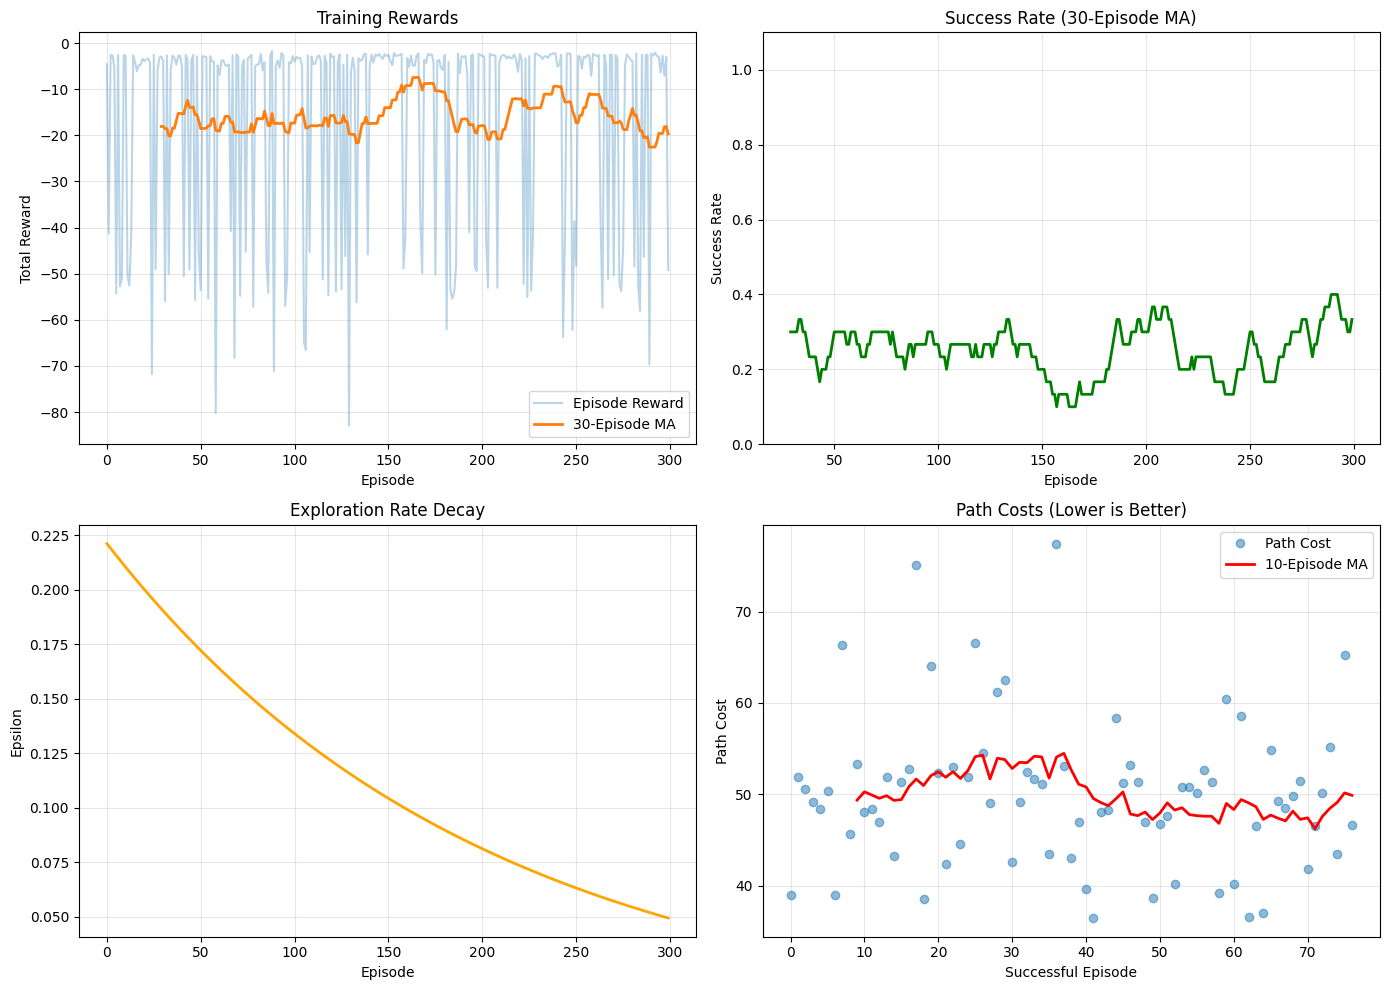

In [38]:
def plot_training_results(rewards, successes, epsilons, costs):
    """Plot training metrics"""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    window = 30
    
    # Plot 1: Rewards
    axes[0, 0].plot(rewards, alpha=0.3, label='Episode Reward')
    if len(rewards) >= window:
        moving_avg = np.convolve(rewards, np.ones(window)/window, mode='valid')
        axes[0, 0].plot(range(window-1, len(rewards)), moving_avg, 
                       linewidth=2, label=f'{window}-Episode MA')
    axes[0, 0].set_xlabel('Episode')
    axes[0, 0].set_ylabel('Total Reward')
    axes[0, 0].set_title('Training Rewards')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    # Plot 2: Success Rate
    if len(successes) >= window:
        success_rate = np.convolve(successes, np.ones(window)/window, mode='valid')
        axes[0, 1].plot(range(window-1, len(successes)), success_rate, 
                       linewidth=2, color='green')
    axes[0, 1].set_xlabel('Episode')
    axes[0, 1].set_ylabel('Success Rate')
    axes[0, 1].set_title(f'Success Rate ({window}-Episode MA)')
    axes[0, 1].grid(True, alpha=0.3)
    axes[0, 1].set_ylim([0, 1.1])
    
    # Plot 3: Epsilon Decay
    axes[1, 0].plot(epsilons, linewidth=2, color='orange')
    axes[1, 0].set_xlabel('Episode')
    axes[1, 0].set_ylabel('Epsilon')
    axes[1, 0].set_title('Exploration Rate Decay')
    axes[1, 0].grid(True, alpha=0.3)
    
    # Plot 4: Path Costs
    if costs:
        axes[1, 1].plot(costs, alpha=0.5, marker='o', linestyle='', label='Path Cost')
        if len(costs) >= 10:
            cost_ma = np.convolve(costs, np.ones(10)/10, mode='valid')
            axes[1, 1].plot(range(9, len(costs)), cost_ma, 
                           linewidth=2, color='red', label='10-Episode MA')
        axes[1, 1].set_xlabel('Successful Episode')
        axes[1, 1].set_ylabel('Path Cost')
        axes[1, 1].set_title('Path Costs (Lower is Better)')
        axes[1, 1].legend()
        axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

plot_training_results(rewards, successes, epsilons, costs)

## 9. Test the Trained Agent

In [39]:
def test_agent(env, agent, num_episodes=5, verbose=True):
    """Test the trained agent"""
    original_epsilon = agent.epsilon
    agent.epsilon = 0  # Pure exploitation
    
    test_results = []
    
    for episode in range(num_episodes):
        state = env.reset()
        done = False
        steps = 0
        path = [env.current_state.copy()]
        
        if verbose:
            print(f"\n=== Test Episode {episode + 1} ===")
            print(f"Initial state: {env.current_state}")
        
        while not done and steps < 30:
            num_available = len(env.available_actions)
            if num_available == 0:
                break
            
            action_idx = agent.choose_action(state, num_available)
            action = env.available_actions[action_idx]
            
            if verbose:
                print(f"  Step {steps}: Action = {action}")
            
            next_state, reward, done, info = env.step(action_idx)
            path.append(env.current_state.copy())
            
            state = next_state
            steps += 1
            
            if done:
                if info.get('success'):
                    cost = info.get('cost', 0)
                    if verbose:
                        print(f"  ✓ SUCCESS!")
                        print(f"    Path cost: {cost:.2f}")
                        print(f"    Final state: {env.current_state}")
                else:
                    if verbose:
                        print(f"  ✗ FAILED: {info.get('reason', 'Unknown')}")
                
                test_results.append(info)
    
    agent.epsilon = original_epsilon
    
    # Summary
    successes = sum(1 for r in test_results if r.get('success', False))
    print(f"\n=== Test Summary ===")
    print(f"Success rate: {successes}/{num_episodes} ({successes/num_episodes*100:.1f}%)")
    
    successful_tests = [r for r in test_results if r.get('success', False)]
    if successful_tests:
        avg_cost = np.mean([r['cost'] for r in successful_tests])
        print(f"Average path cost: {avg_cost:.2f}")
    
    return test_results

# Test the agent
test_results = test_agent(env, agent, num_episodes=5, verbose=True)


=== Test Episode 1 ===
Initial state: State(v=0, t=0.00, parked=False)
  Step 0: Action = ('drive', 1)
  Step 1: Action = ('drive', 8)
  Step 2: Action = ('drive', 9)
  Step 3: Action = ('drive', 10)
  Step 4: Action = ('drive', 13)
  Step 5: Action = ('drive', 14)

=== Test Episode 2 ===
Initial state: State(v=0, t=0.00, parked=False)
  Step 0: Action = ('drive', 1)
  Step 1: Action = ('drive', 8)
  Step 2: Action = ('drive', 9)
  Step 3: Action = ('drive', 10)
  Step 4: Action = ('drive', 11)
  Step 5: Action = ('drive', 14)

=== Test Episode 3 ===
Initial state: State(v=0, t=0.00, parked=False)
  Step 0: Action = ('drive', 1)
  Step 1: Action = ('drive', 8)
  Step 2: Action = ('drive', 9)
  Step 3: Action = ('drive', 10)
  Step 4: Action = ('drive', 11)
  Step 5: Action = ('park', 11)
  ✓ SUCCESS!
    Path cost: 39.37
    Final state: State(v=11, t=23.34, parked=True)

=== Test Episode 4 ===
Initial state: State(v=0, t=0.00, parked=False)
  Step 0: Action = ('drive', 1)
  Step 1: A


### 10. Summary of Search Problem Components

### Implemented Functions:

1. **State Representation**: s = (v, t, A[t], C[t])
   - v: current vehicle position
   - t: current time
   - A[t]: parking availability
   - C[t]: parking costs

2. **Initial_State(network, t0)**: s₀ = (S, t₀, A(t₀), C(t₀))

3. **Actions(state, network)**:
   - Navigate: drive along edge ⟨v, u⟩
   - Park: commit to parking lot pₖ

4. **Transition_Model(state, action, network)**:
   - Updates position and time
   - Updates availability and costs
   - Handles dynamic conditions

5. **Goal_Test(state, network, W_max)**:
   - Vehicle parked at pₖ
   - Aₖ(t) > 0
   - W(pₖ, D) ≤ W_max

6. **Path_Cost(path, network, α, β)**:
   - PathCost = driving_time + α·W(pₖ, D) + β·cₖ(t)

### Next Steps:
- Experiment with different α and β values
- Try different network configurations
- Implement more sophisticated search algorithms (A*, Dijkstra)
- Add real-world constraints (traffic lights, one-way streets)